# **08. Visualization in Python**

In this class we will be using another Python library to visualize data: **Seaborn**.
We are going to use the Tips dataset.

Tips is a dataset that refers to the person that pay:
- day: day of the week
- total_bill: bill in dollars
- tip: tip
- time: lunch or dinner
- size: number of persons

In [1]:
import pandas as pd # import pandas
import numpy as np # import numpy
import matplotlib.pyplot as plt # import library to plot

In [28]:
!pip install seaborn  #We have to install seaborn

In [7]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
%cd /content/drive/MyDrive/Teaching/Python_for_data_analytics/Notebooks theory
#Remember this is my path to the file, porbably you do not have the folder Programming II, so the next line would be ok if you upload the file to Colab Notebooks folder
#%cd /content/drive/MyDrive/Colab\ Notebooks

!ls

/content/drive/MyDrive/Teaching/Python_for_data_analytics/Notebooks theory
 01_Hello_Python_ProgII_24.ipynb	    'Data visualization - Matplotlib.ipynb'
'02_Data structures_Lists_ProgII_24.ipynb'   foods.csv
 03_while_loop_input_csv_ProgII_24.ipynb     HDI.csv
'04_Dictionaries in Python_ProgII24.ipynb'   HousePrices.csv
'05_Functions in Python_ProgII_24.ipynb'     iris.csv
 06_Numpy_ProgII_24.ipynb		     movies.csv
'07_Pandas III_ProgII_24.ipynb'		     nba.csv
'07_Pandas II_ProgII_24.ipynb'		     NBA-playerlist.csv
'07_Pandas I_ProgII_24.ipynb'		     PPR-2015.csv
 08_Visualization_ProgII_24.ipynb	     tips.csv
 billionaires.csv			     UN98.csv
 CASchools.csv				     worldstats.csv


In [4]:
#explore the dataset
tips = pd.read_csv('datos/tips.csv')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [32]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


Take a look that in this dataframe we have variables that are of the type ``object``, and those are categorical variables.

In [33]:
#Let's check that there are not NAs
tips.isnull().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


In [ ]:
tips.describe() #To follow show some statistics of the variables

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## Seaborn syntax
Seaborn is built on top of Matplotlib and provides a high-level interface for creating informative statistical graphics. Its syntax usually turns out to be simpler than Matplotlib, although Matplotlib may result more customizable.

## Seaborn advantages:
- Simpler syntax
- A number of themes for data visualization
- Offers better pandas datasets handling









## Basic types of graphs

These are the types of graphs that are commonly used to explore data.

- **Scatter plots**
- **Line plots**
- **Bar plots**
- **Histograms**
- **Box plots**
- **Kernel Density Estimation Plots**
- **Violin plots**


### Scatter plots

Scatter plots display the relationship between two variables as points on the graph. In simple terms, the values of one variable **x** are plotted on the horizontal axis against the values of another variable **y** on the vertical axis.



**Note**: The IPython magic command `%matplotlib inline` allows displaying plots in the Notebook. If we don't include it, the plots won't be embedded in the Notebook.

#### Scatter plots with Seaborn

 There are many functions in Seaborn, but we will see some of them:
- _displot_ (distributions of one or two variables),     with: histplot, kdeplot, ecdfplot, rugplot
- _relplot_ (relation between two variables, usually continuous), with: scatterplot, lineplot
- _catplot_ (when we have categorical variables)
    with: stripplot, swarmplot, boxplot, violinplot,
     pointplot, barplot

  
Let's explore the relationship between the number of people who attended and the tips they gave.

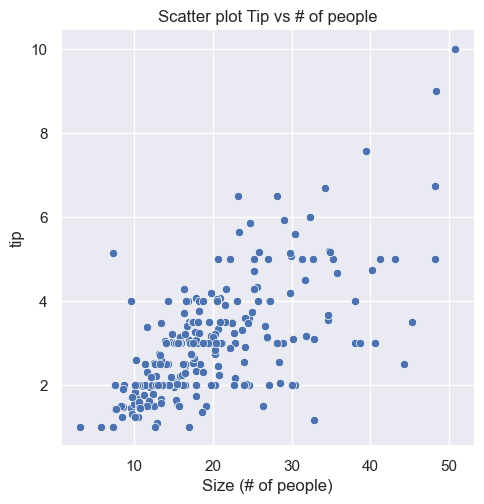

In [9]:
#sns.relplot(data=housing, x="DIS", y="tip", hue="smoker");
sns.set(style="darkgrid") #With this, the plotting area is going to be shaded
sns.relplot(data=tips, x="total_bill", y="tip", kind="scatter").set(title='Scatter plot Tip vs # of people', xlabel='Size (# of people)', ylabel='tip')
plt.show()

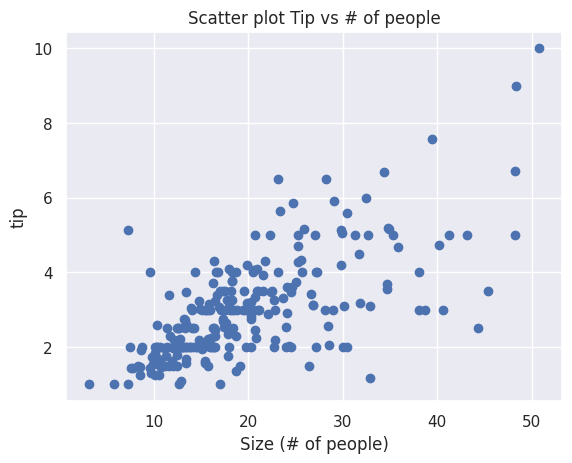

In [ ]:
#The equivalent code in MAtplotlib:
plt.scatter(tips["total_bill"], tips["tip"])

# Set labels and title
plt.xlabel("Size (# of people)")
plt.ylabel("tip")
plt.title("Scatter plot Tip vs # of people")

# Show the plot
plt.show()

What can we say about the relationship?
For instance, let's plot a regression line of X on Y.

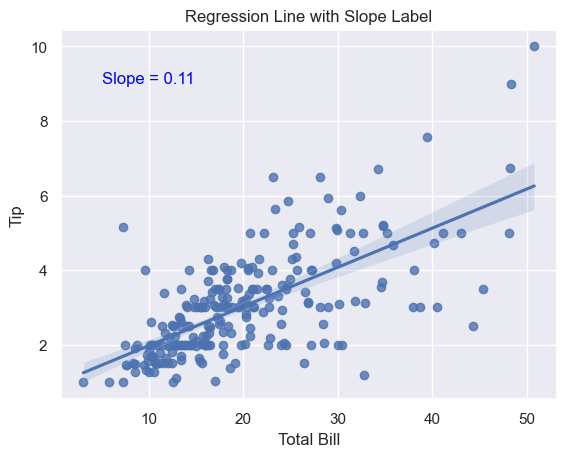

In [10]:
from scipy.stats import linregress

#sns.relplot(data=housing, x="DIS", y="tip", hue="smoker");
sns.set(style="darkgrid")

# Run linear regression
slope, intercept, r_value, p_value, std_err = linregress(tips["total_bill"], tips["tip"])

# Create plot
sns.regplot(data=tips, x="total_bill", y="tip", ci=90)

# Add slope label
slope_label = f"Slope = {slope:.2f}"
plt.text(x=5, y=9, s=slope_label, fontsize=12, color='blue')  # Adjust position as needed

# Titles and labels
plt.title('Regression Line with Slope Label')
plt.xlabel('Total Bill')
plt.ylabel('Tip')

plt.show()


### Line plots with Seaborn

We will use the command ``relplot`` from Seaborn, as before, but specifying that is a line.

In [34]:
#create a dataset with the square value of numbers from 0 to 100
import pandas as pd
x = list(range(100))
y = [z * z for z in range(100)]
df = pd.DataFrame({'x':x, 'y':y})

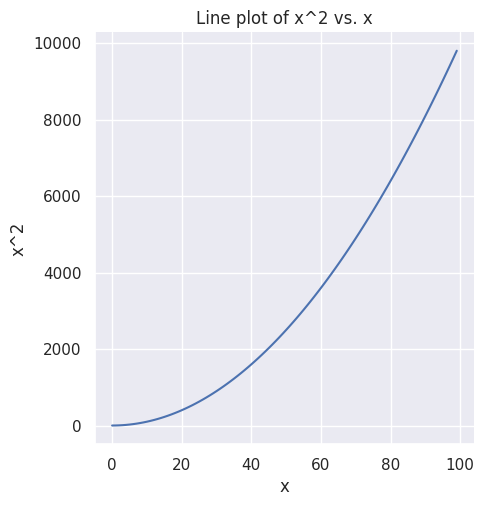

In [35]:
sns.relplot(data=df, x="x", y="y", kind="line").set(title='Line plot of x^2 vs. x', xlabel='x', ylabel='x^2');
plt.show()

### Bar plots (with matplotlib)

Bar plots are used to display the counts of unique values of a categorical variable (among other things). The height of the bar represents the count for each unique category of the variable.

It's unlikely that in the DataFrame we have a count per category of a variable. Therefore, the first step to make a bar plot is to calculate the frequencies. Fortunately, pandas has a method called ``value_counts``.

You will see that seaborn makes this task easier.

In [ ]:
# plot number of smokers in the dataset
counts = tips['smoker'].value_counts()

Now we can create the bar plot using the variable ``counts``.

Text(0, 0.5, '# of people')

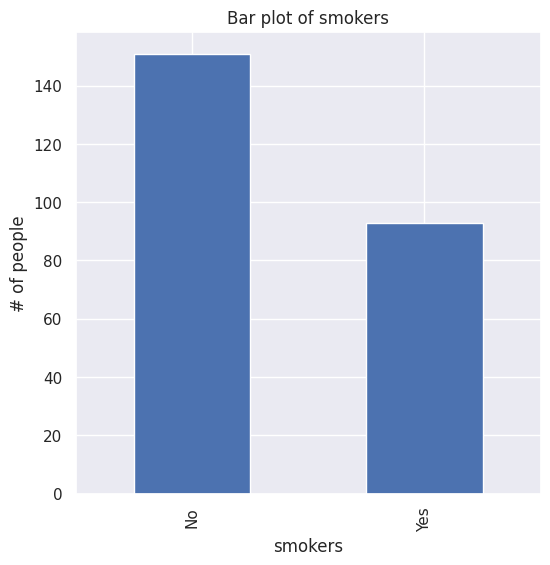

In [36]:
fig = plt.figure(figsize=(6,6)) # define plot area
ax = fig.gca() # define axis
counts.plot.bar(ax = ax) # Use the plot.bar method on the counts data frame
ax.set_title('Bar plot of smokers') # Give the plot a main title
ax.set_xlabel('smokers') # Set text for the x axis
ax.set_ylabel('# of people')# Set text for y axis

### Bar plots in Seaborn

In Seaborn, we use the ``catplot`` function, with the option ``kind`` equal to count.

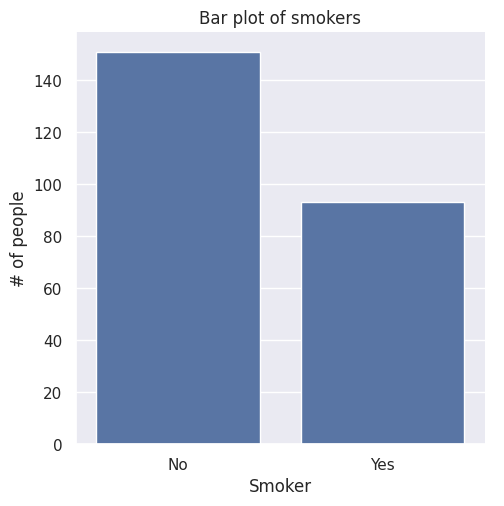

In [ ]:
sns.catplot(data=tips, x="smoker", kind="count").set(title='Bar plot of smokers', xlabel='Smoker', ylabel='# of people');
plt.show()

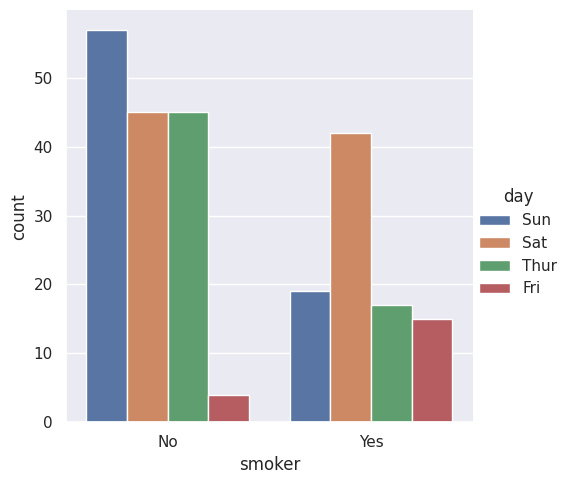

In [ ]:
#Smokers by day of the week
sns.catplot(data=tips, x="smoker", hue="day", kind="count") #parameter hue divides the plot into sub-bars accounting for week days
plt.show()

In Seaborn, the barplot function works in a complete dataset and applies a function to obtain an estimation (taking the mean as default). When we have multiple observations in each category, it also uses bootstrapping to calculate the confidence interval (95% by default) around the estimation and draw error bars:

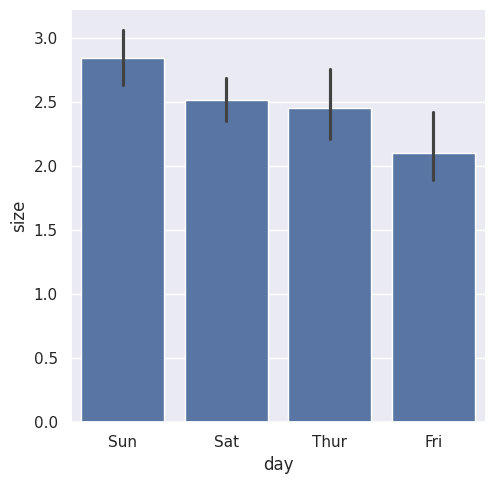

In [ ]:
sns.catplot(data=tips, x="day", y="size", kind="bar")
plt.show()

### Histograms with Pandas


Histograms are related to bar plots. Histograms are used to represent numerical variables. While a bar plot shows the counts of unique categories, a histogram shows the amount of data with values within a bin. The bins divide the values of the variable into equal segments. The vertical axis of the histogram shows the count of data values within each bin.
The following code showa how to create a histogram with the variable ``MEDV``.

### Histograms with Seaborn

In Seaborn we use the ``displot`` function. With this function, we can also control for the number of bins in the histogram.

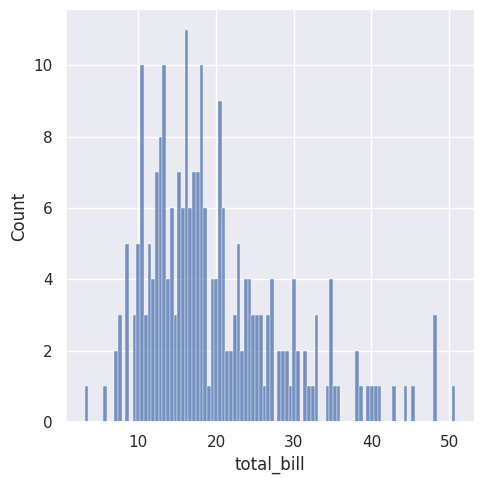

In [40]:
#Calculating the distribution function with an histogram of 40 bins
sns.displot(data=tips, x='total_bill', kind="hist", bins=100, fill=True);
plt.show()

Besides, we can create different histograms depending on the values of a categorical variable defined in ``col``.

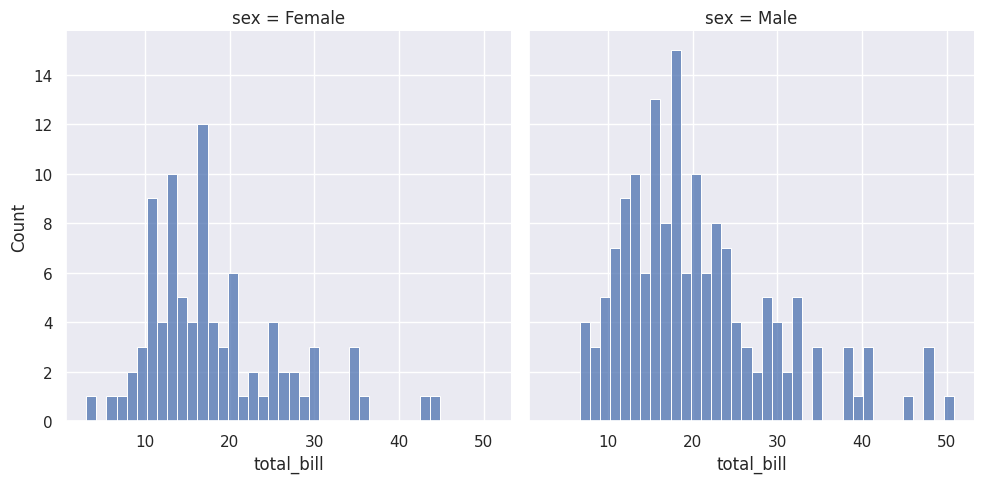

In [ ]:
#Calculating the distribution function with an histogram of 40 bins
sns.displot(data=tips, x='total_bill', kind="hist", col='sex', bins=40, fill=True);
plt.show()

**FINDING:** The more bins in the histogram, the more similar to the distribution of the variable.

### Boxplots with Seaborn

In Seaborn we use the catplot (categorical variables) using ``kind="box"``.

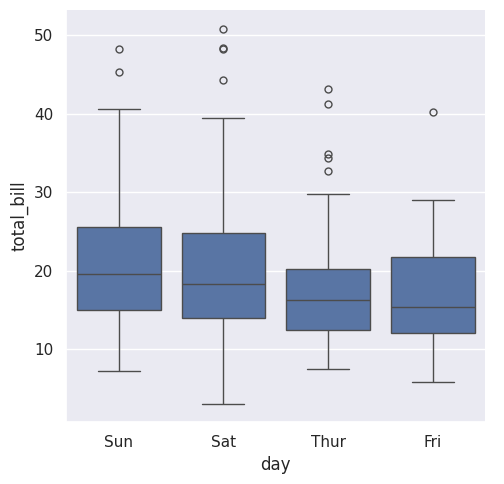

In [ ]:
#we can add more variables with hue
sns.catplot(data=tips, x="day", y="total_bill", kind="box")
plt.show()

We can add more variables using the option ``hue``.

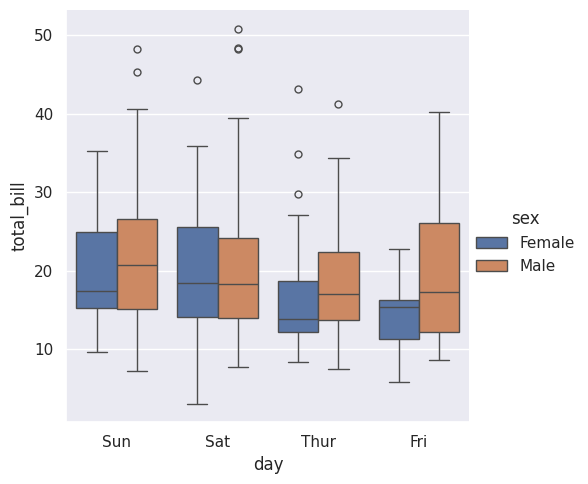

In [ ]:
#we can add more variables with hue
sns.catplot(data=tips, x="day", y="total_bill", hue="sex", kind="box")
plt.show()

### Kernel Density Plots using Seaborn
Seaborn is a newer Python package that abstracts matplotlib plots. Seaborn implements some more modern types of plots.

Kernel density plots are conceptually similar to a histogram. A kernel density plot displays the values of a histogram in a smoothed, curved form.

In the code of the next cell, we:

- Import the Seaborn package,
- Set a grid style for plotting.
- Define the plot type with kdeplot using the column engine-size as an argument.

From help(sns.displot):
_This function provides access to several approaches for visualizing the univariate or bivariate distribution of data_.

<Axes: xlabel='total_bill', ylabel='Density'>

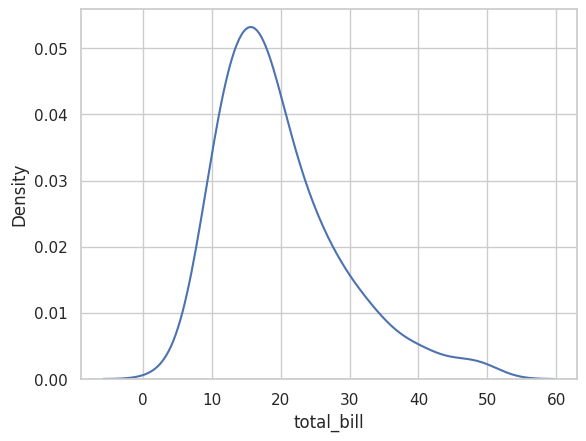

In [ ]:
import seaborn as sns
sns.set_style("whitegrid")
sns.kdeplot(tips['total_bill'])

As we did with Pandas plots, we control the properties of a Seaborn plot by specifying the axes. The code in the cell below extends our Seaborn plotting code:

- Define a figure.
- Define one or more axes in the figure.
- Set a grid style for the plot.
- Define the plot type and the columns to be drawn.
- Use methods on the axes to control attributes such as title and axis labels.

Text(0, 0.5, 'Density')

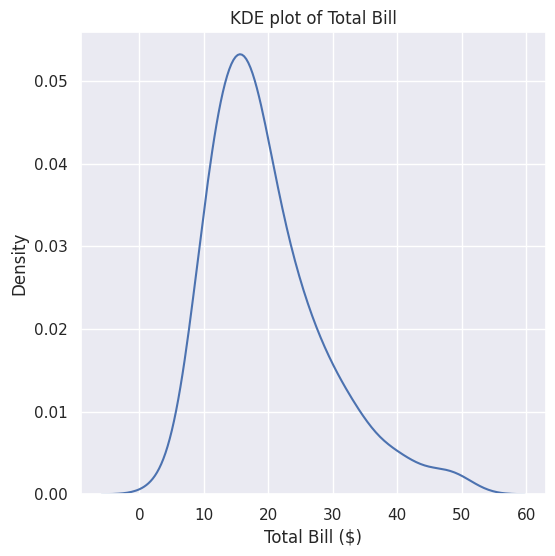

In [ ]:
fig = plt.figure(figsize=(6,6)) # define plot area
ax = fig.gca() # define axis
sns.set_style("whitegrid")
sns.kdeplot(tips['total_bill'], ax = ax)
ax.set_title('KDE plot of Total Bill') # Give the plot a main title
ax.set_xlabel('Total Bill ($)') # Set text for the x axis
ax.set_ylabel('Density')# Set text for y axis

Using ``hue`` we can group variables and calculate their density distributions.

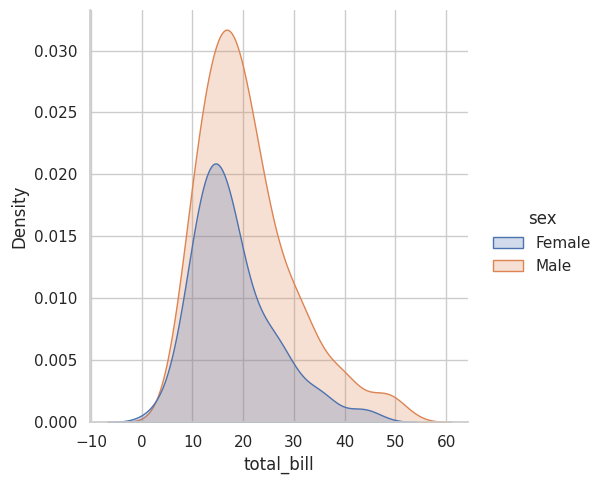

In [ ]:
# We represent the bills against sex (hue)
sns.displot(data=tips, x='total_bill', hue='sex', kind="kde", fill=True);
plt.show()

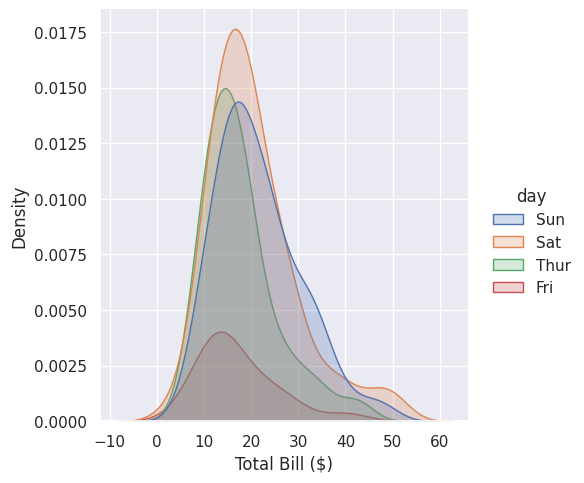

In [ ]:
# We represent the bills against sex (hue)
# Create the KDE plot
g= sns.displot(data=tips, x='total_bill', hue='day', kind="kde", fill=True)

# Set the x-axis label
g.ax.set_xlabel("Total Bill ($)")
plt.show()

We also can create a bidimensional plot of KDE.

### Violin plots


Now, we will use Seaborn to create a violin plot. A violin plot combines the attributes of box plots and a KDE. Like a box plot, violin plots can be stacked, with one group per operation. Additionally, the violin plot provides a kernel density estimation for each group. Similar to the box plot, violin plots allow displaying two dimensions of the data.

The ``sns.violinplot`` method has more arguments than the kdeplot method.

- The columns used for the plot are set with the arguments ``x`` and ``y``.
- The ``x`` column is the group by variable.
- The ``data`` argument specifies a DataFrame or a numpy array.

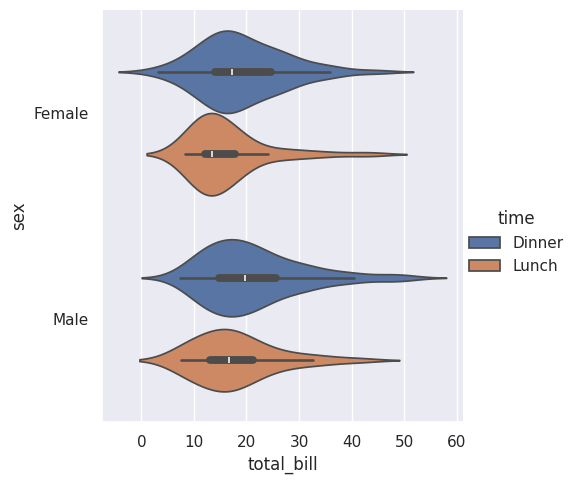

In [ ]:
sns.catplot(data=tips, x="total_bill", y="sex", hue="time", kind="violin");
plt.show()

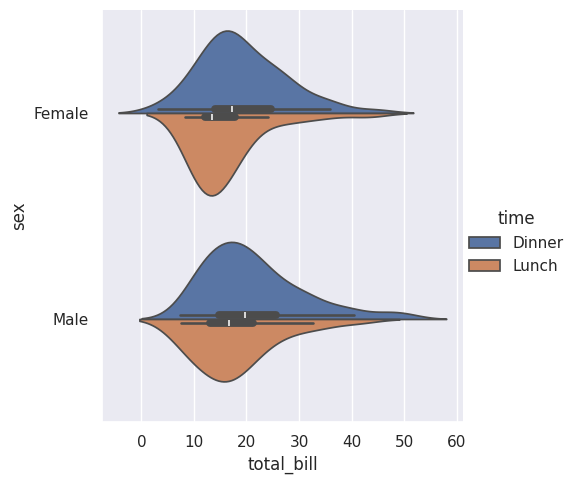

In [ ]:
#Using split=True we do not duplicate the distribution of the variable
sns.catplot(data=tips, x="total_bill", y="sex", hue="time", kind="violin", split=True);
plt.show()

##Mixing plots in Seaborn

In seaborn we can mix different type of plots. We are going to use the function ``catplot`` that has been used before to do some boxplots. Remember that one of the variables has to be categorical.

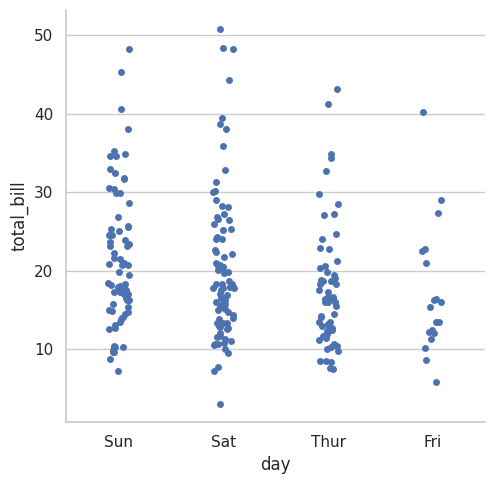

In [ ]:
# By default it uses kind="strip". Remember that "day" es categorical and "total_bill" numeric
sns.catplot(data=tips, x="day", y="total_bill")
plt.show()

If we use the option ``swarm`` we avoid superposition plotting the values of the distributions.

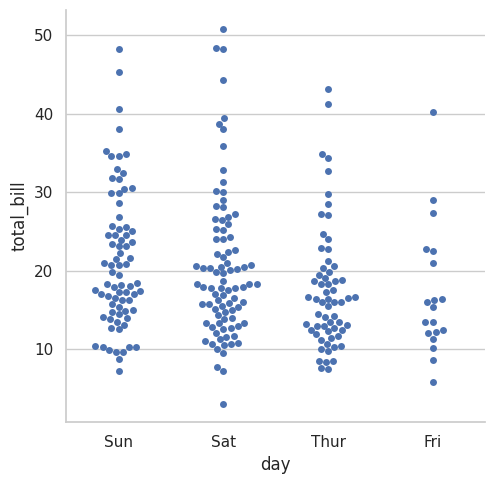

In [ ]:
sns.catplot(data=tips, x="day", y="total_bill", kind="swarm")
plt.show()

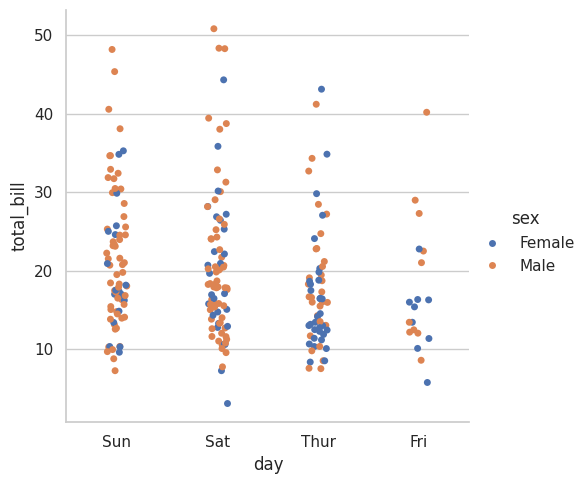

In [ ]:
sns.catplot(data=tips, x="day", y="total_bill", hue="sex")
plt.show()

Let's mix some plots in the same one. We are going to mix a violin plot with the values of the distributions

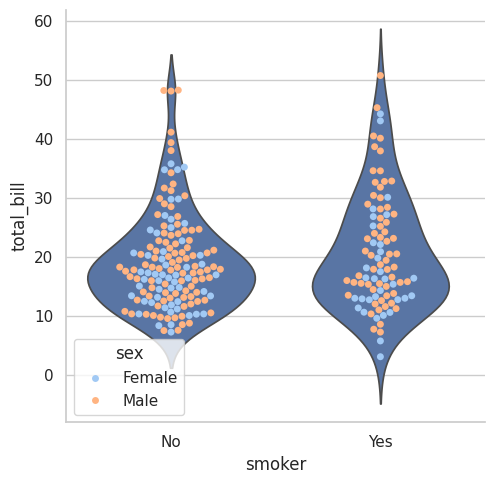

In [ ]:
#we can mix graphics in the same one
g = sns.catplot(x="smoker", y="total_bill", kind="violin", inner=None, data=tips)
sns.swarmplot(x="smoker", y="total_bill", hue="sex", palette="pastel", data=tips, ax=g.ax);
plt.show()

## Multi-axis y Facet Plots

We have explored the types of basic plots and the use of their properties to project multiple dimensions. Now we will investigate the use of multiple axes graphs. Multiple axes diagrams use an array of axes to display relationships in a dataset. Multiple axes plot diagrams include matrices of scatter plots and a technique known as **faceting**. Faceting involves the use of values ​​from categorical or numerical variables to create a set of related graphics.

### Pair plot with marginal density

One type of simple multiple axes diagram is a scatter plot with the marginal density of each dimension displayed along the horizontal or vertical axis.

We use the ``jointplot`` method from Seaborn to create such a graph. Specify the columns to be plotted on the x and y axes. The transparency argument ``alpha`` is specified to handle overplotting.

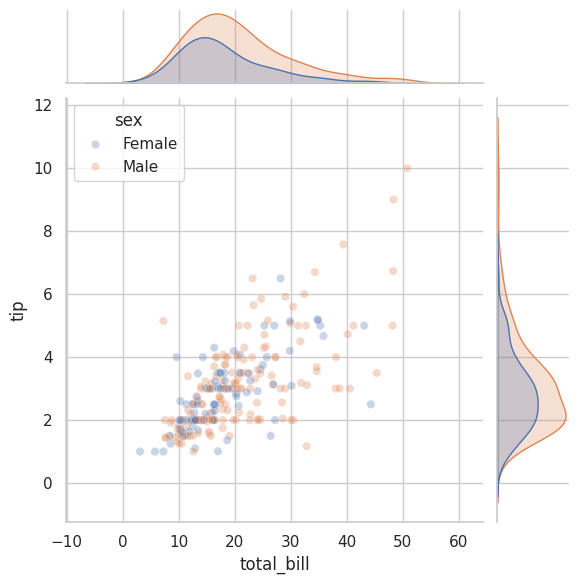

In [ ]:
sns.set_style("whitegrid")
sns.jointplot(data=tips, x="total_bill", y= "tip", hue="sex", alpha=0.3)
plt.show()

### Pair wise plots (numerical variables)

Pairwise plots, also known as plot matrices, allow us to see multiple dimensions of a dataset in a single plot. A scatter plot of each variable against all other variables is displayed, arranged in a matrix. Another type of diagram, such as a KDE plot, can be shown for each variable pair. Different types of plots can be placed along the diagonal of the matrix.


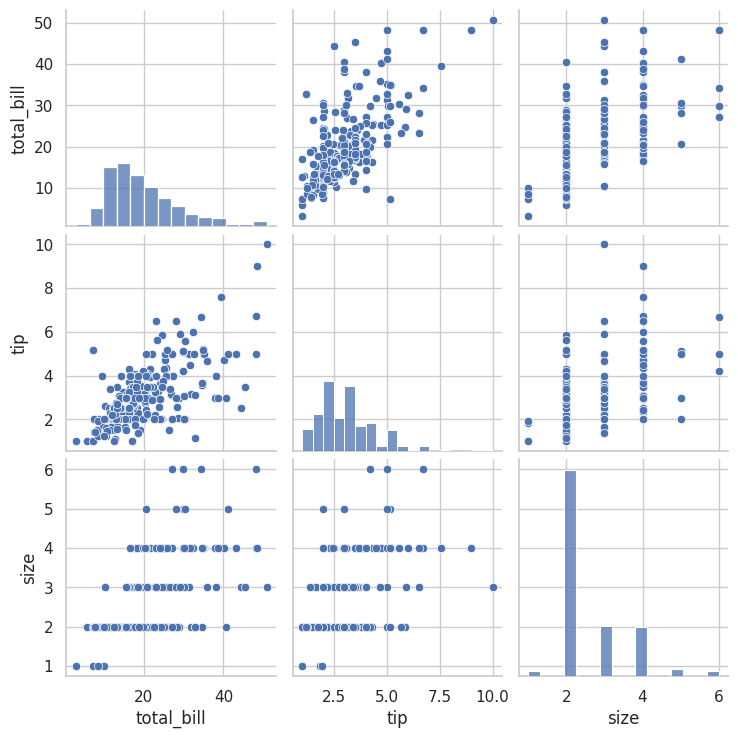

In [ ]:
sns.pairplot(tips)


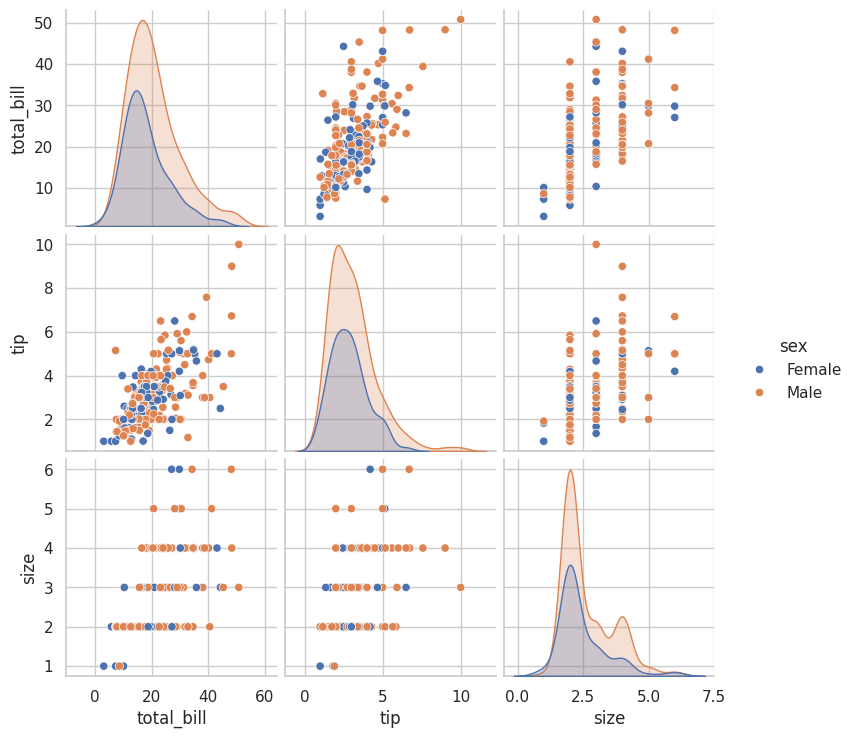

In [ ]:
sns.pairplot(tips,hue='sex')

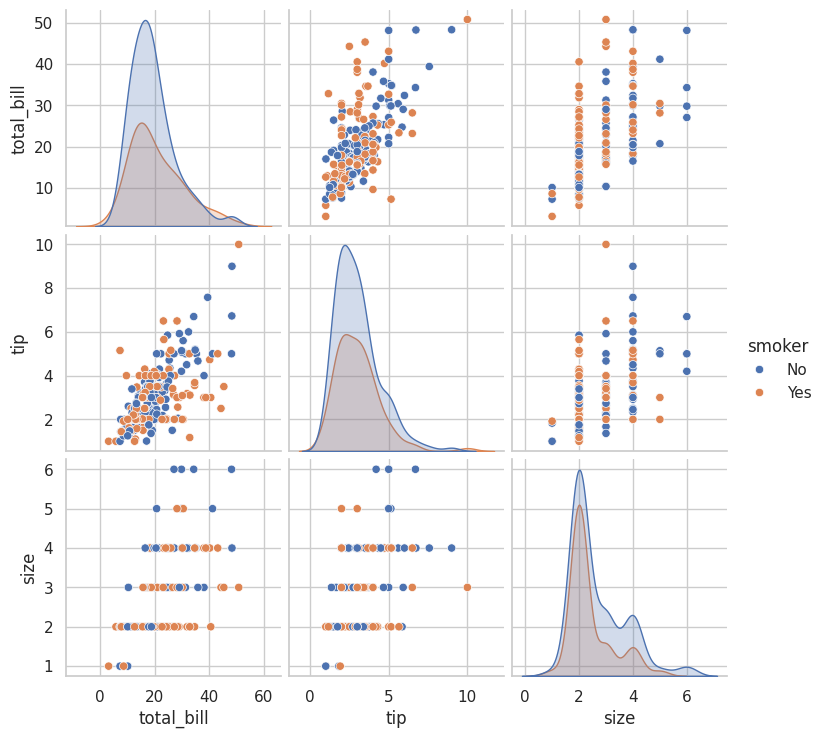

In [ ]:
sns.pairplot(tips,hue='smoker')

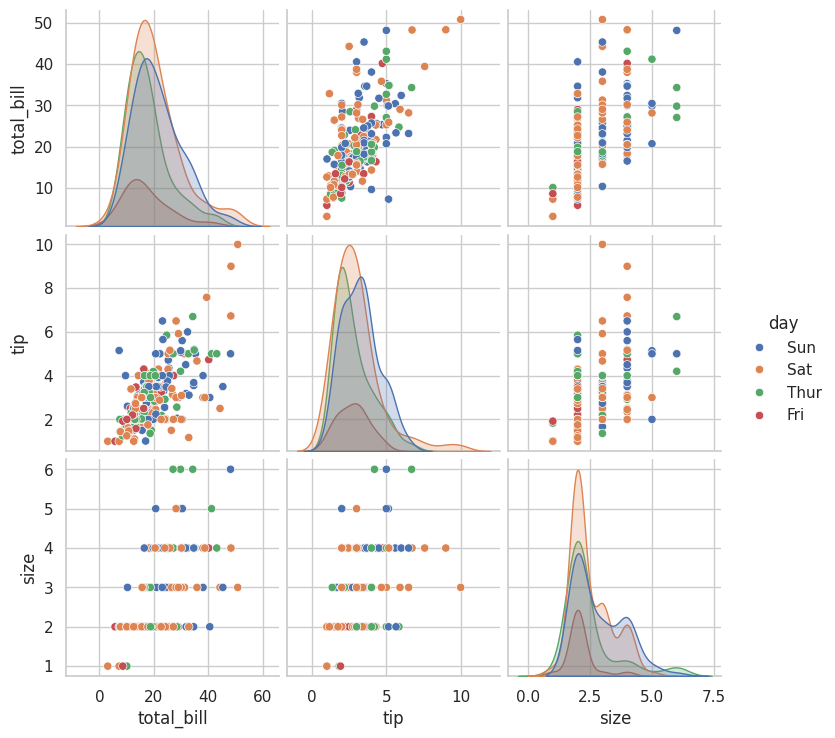

In [ ]:
sns.pairplot(tips,hue='day')

### Facet plots

We can create plots with multiple axes, combining variables. Using ``FacetGrid`` method, we indicate that we want two different axes depending on ``sex``. Then, we add the type of graph we want to use.

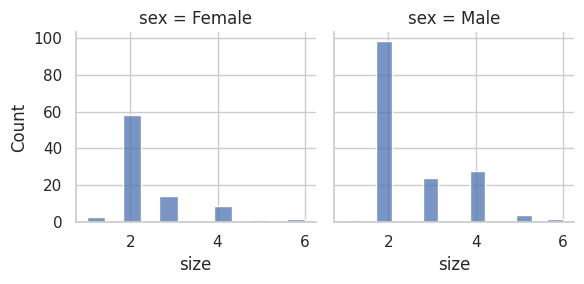

In [ ]:
# First we define a graph with the dataset and other data
g = sns.FacetGrid(tips, col="sex")
# Then we add the type of graph to use
g.map(sns.histplot, "size")
plt.show()

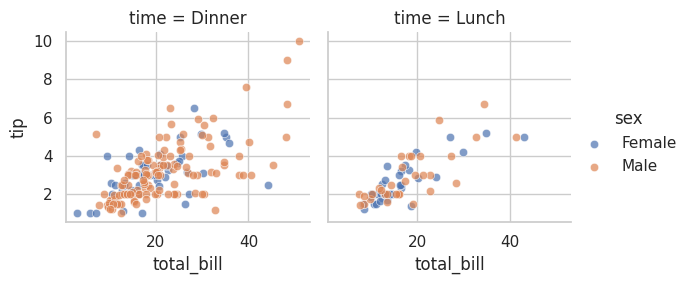

In [ ]:
# It can be more complex
g = sns.FacetGrid(tips, col="time", hue="sex")
g.map(sns.scatterplot, "total_bill", "tip", alpha=.7)
g.add_legend()
plt.show()

In [ ]:
g = sns.FacetGrid(tips, col="day")
g.map(sns.regplot, "e", "price", fit_reg = False)

## Heatmaps

Another type of very interesting plots are heatmaps, which allow for easy visualization of three variables at once. Usually, you choose the x and y axes, and the third variable is represented through the color intensity, which varies on a scale from low to high.

To create the representation, it's necessary to prepare the data by creating a data matrix with x axes represented by the rows and the y axis by the columns. The color is defined by the value in the cells. Different color patterns can be created using the [*cmap*](https://matplotlib.org/examples/color/colormaps_reference.html) parameter, which allows you to select the colormap to use.

<Axes: xlabel='sex', ylabel='day'>

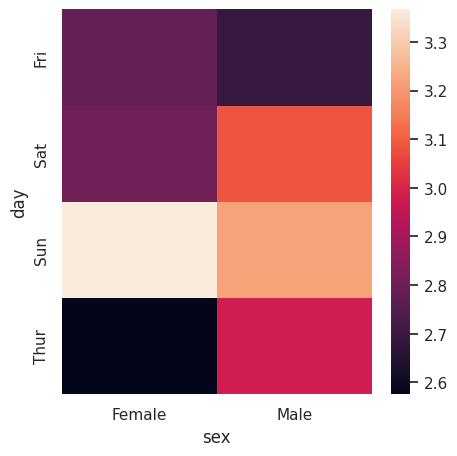

In [ ]:
a = pd.pivot_table(tips, index='day',
columns='sex', values='tip', aggfunc='mean')
fig = plt.figure(figsize=(5,5)) # define plot area
ax = fig.gca() # define axis
sns.heatmap(a, axes=ax)